# Module 20.1 — Initial Report and Exploratory Data Analysis
## Predicting trade settlement failures before settlement

**Data:** 25,000 synthetic trades dated 2023–2025. **Research question:** Can information available before settlement identify trades at elevated risk of failing settlement?

**Scope:** Initial EDA, cleaning audit, feature engineering, and one interpretable **Logistic Regression baseline**. Advanced models and final comparisons are reserved for Module 24. All figures and metrics are based on **synthetic data**; they are not production estimates.

## 1. Business problem and hypothesis
Failed trades can create operational rework, liquidity demands, and settlement penalties. Early risk identification could help operations teams prioritize review.

**Hypothesis:** Pre-settlement operational friction (e.g., confirmation delays, SSI changes, matching attempts, shortfalls) is associated with higher settlement-failure risk. This is exploratory association, not causal proof.

**Prediction target:** `settlement_failed` (1 = failed, 0 = settled). **Primary evaluation metric:** Average Precision / PR-AUC because failures are rare. Report ROC-AUC, precision, recall, F1 and confusion matrix as supporting metrics. A no-skill PR-AUC equals the failure prevalence in the evaluation set.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.dummy import DummyClassifier
sns.set_theme(style='whitegrid', context='notebook')
DATA = Path('data/trade_settlement_synthetic.csv')
assert DATA.exists(), f'Missing {DATA}. Run notebook from project root.'
df = pd.read_csv(DATA, parse_dates=['trade_date','settlement_date'])
print('Dataset shape:', df.shape)
display(df.head(5))

Dataset shape: (25000, 37)


,trade_id,trade_date,settlement_date,asset_class,buy_sell,currency,market,settlement_location,counterparty_id,custodian,...,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,counterparty_avg_trade_amount,trade_size_ratio,pre_settlement_note,settlement_failed,settlement_delay_hours,failure_reason,failure_reason_description
0,TRD0001488,2023-01-02,2023-01-04,ETF,BUY,CAD,EU,JASDEC,CP074,CUST04,...,0.4493,22.74,0,1997496.48,0.0895,late confirmation,0,0.04,SETTLED,Trade settled successfully with no final excep...
1,TRD0002259,2023-01-02,2023-01-04,Equity,SELL,USD,US,DTC,CP042,CUST11,...,0.9253,12.86,0,296082.56,2.4813,settlement instruction recently changed,0,0.12,SETTLED,Trade settled successfully with no final excep...
2,TRD0002316,2023-01-02,2023-01-04,Corporate Bond,SELL,USD,US,DTC,CP071,CUST12,...,0.9333,15.91,0,1653138.14,0.6905,normal pre-settlement processing,0,0.30,SETTLED,Trade settled successfully with no final excep...
3,TRD0002442,2023-01-02,2023-01-04,ETF,BUY,GBP,JP,JASDEC,CP005,CUST09,...,0.6167,12.99,0,625360.40,0.5844,normal pre-settlement processing,0,0.69,SETTLED,Trade settled successfully with no final excep...
4,TRD0003674,2023-01-02,2023-01-04,Equity,SELL,USD,US,DTC,CP047,CUST10,...,0.3952,29.78,0,506657.23,1.1998,normal pre-settlement processing,0,0.00,SETTLED,Trade settled successfully with no final excep...


## 2. Data origin and dictionary
The CSV is a **synthetically generated** trade-level dataset, not an independently acquired live trading feed. It simulates trade booking, counterparties, custodians, market conditions, and pre-settlement operations. Its labels are simulated outcomes. Post-settlement fields (`settlement_delay_hours`, `failure_reason`, `failure_reason_description`) are **not allowed as predictors**. `trade_id` is an identifier, not a feature. `pre_settlement_note` is not included in the baseline because free text would require a separate, carefully audited text pipeline.

The source has 37 fields. The table below summarizes types, missingness, and examples.

In [2]:
profile = pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'missing_pct':df.isna().mean()*100,'unique':df.nunique(dropna=False)})
display(profile)
print('Date range:', df.trade_date.min().date(), 'to', df.trade_date.max().date())
print('Failure count:', int(df.settlement_failed.sum()), 'of', len(df))

,dtype,missing,missing_pct,unique
trade_id,str,0,0.0,25000
trade_date,datetime64[us],0,0.0,760
settlement_date,datetime64[us],0,0.0,1030
asset_class,str,0,0.0,4
buy_sell,str,0,0.0,2
currency,str,0,0.0,5
market,str,0,0.0,5
settlement_location,str,0,0.0,6
counterparty_id,str,0,0.0,80
custodian,str,0,0.0,12


Date range: 2023-01-02 to 2025-11-28
Failure count: 489 of 25000


## 3. Data quality audit and cleaning
Audit missing values, duplicate records/IDs, date order, negative monetary amounts, out-of-range historical rates, and invalid target values. **Do not silently delete genuine extremes.** For this dataset, retain all records unless an invalid value is detected. The modeling pipeline includes train-fitted imputers to make the baseline robust to future missing inputs.

In [3]:
audit = {
 'missing_cells':int(df.isna().sum().sum()),
 'duplicate_rows':int(df.duplicated().sum()),
 'duplicate_trade_ids':int(df.trade_id.duplicated().sum()),
 'settlement_before_trade':int((df.settlement_date<df.trade_date).sum()),
 'nonpositive_trade_amount':int((df.trade_amount<=0).sum()),
 'invalid_30d_fail_rates':int((~df.prior_fail_rate_30d.between(0,1)).sum()),
 'invalid_90d_fail_rates':int((~df.prior_fail_rate_90d.between(0,1)).sum()),
 'invalid_target':int((~df.settlement_failed.isin([0,1])).sum())
}
display(pd.DataFrame.from_dict(audit, orient='index', columns=['count']))
assert all(v==0 for v in audit.values()), 'Quality issue: investigate before proceeding.'
clean = df.drop_duplicates(subset='trade_id').copy()
print('Rows retained:',len(clean))

,count
missing_cells,0
duplicate_rows,0
duplicate_trade_ids,0
settlement_before_trade,0
nonpositive_trade_amount,0
invalid_30d_fail_rates,0
invalid_90d_fail_rates,0
invalid_target,0


Rows retained: 25000


## 4. EDA — class balance, numeric variables, categories, and relationships
Plot failures and class rates, continuous-variable distributions, categorical failure rates, correlation, and outliers. For skewed monetary amounts, use log scales. **Group comparisons are descriptive only.**

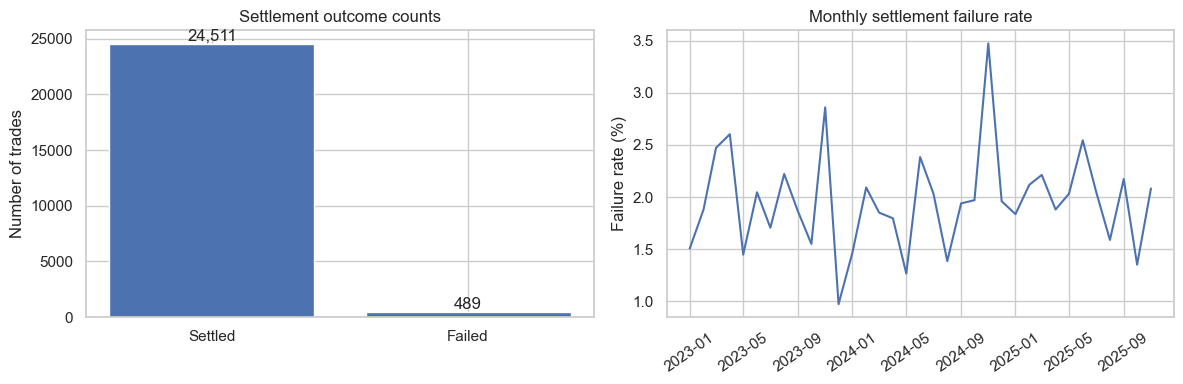

Overall failure rate: 1.96%


In [4]:
fig, ax = plt.subplots(1,2,figsize=(12,4))
counts=clean.settlement_failed.value_counts().sort_index()
ax[0].bar(['Settled','Failed'],counts.values);ax[0].set_title('Settlement outcome counts');ax[0].set_ylabel('Number of trades')
for i,v in enumerate(counts.values):ax[0].text(i,v,f'{v:,}',ha='center',va='bottom')
monthly=clean.assign(month=clean.trade_date.dt.to_period('M').dt.to_timestamp()).groupby('month').settlement_failed.agg(['mean','size'])
ax[1].plot(monthly.index,monthly['mean']*100);ax[1].set_title('Monthly settlement failure rate');ax[1].set_ylabel('Failure rate (%)');ax[1].tick_params(axis='x',rotation=35)
plt.tight_layout();plt.show()
print('Overall failure rate: {:.2%}'.format(clean.settlement_failed.mean()))

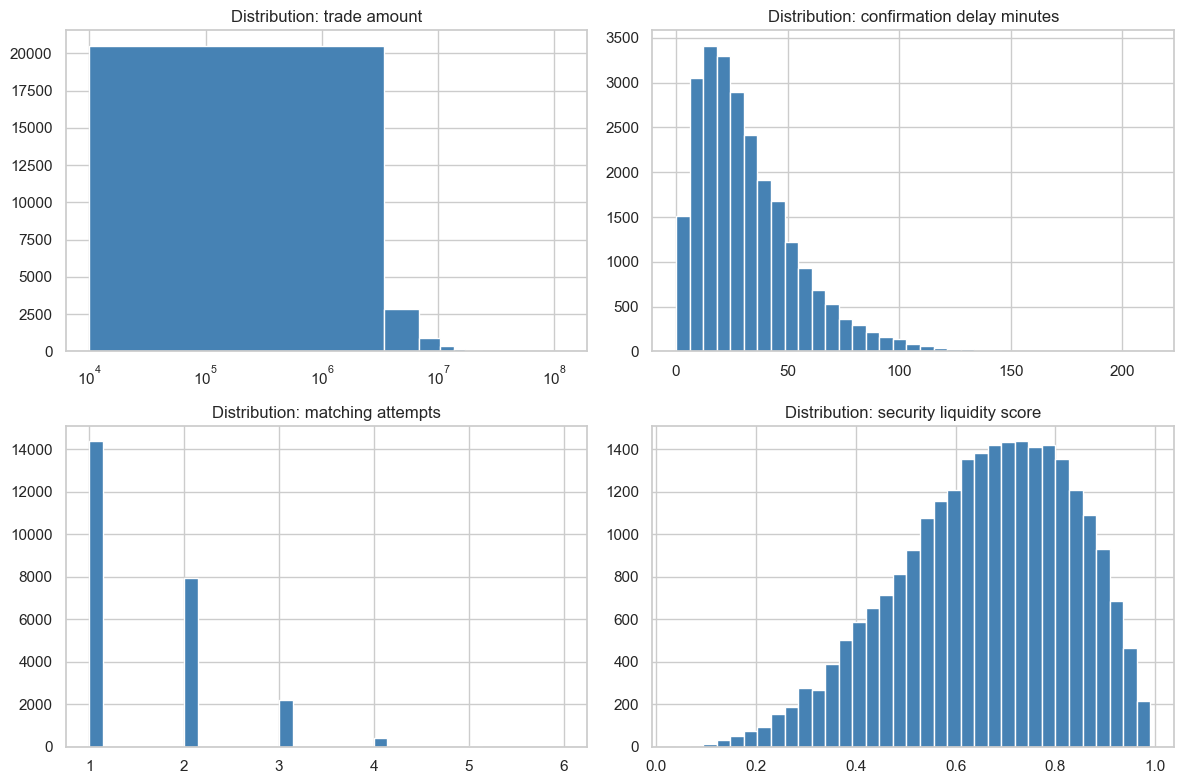

In [5]:
fig, axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,['trade_amount','confirmation_delay_minutes','matching_attempts','security_liquidity_score']):
    ax.hist(clean[col].dropna(),bins=35,color='steelblue')
    if col=='trade_amount':ax.set_xscale('log')
    ax.set_title(f'Distribution: {col.replace("_"," ")}')
plt.tight_layout();plt.show()

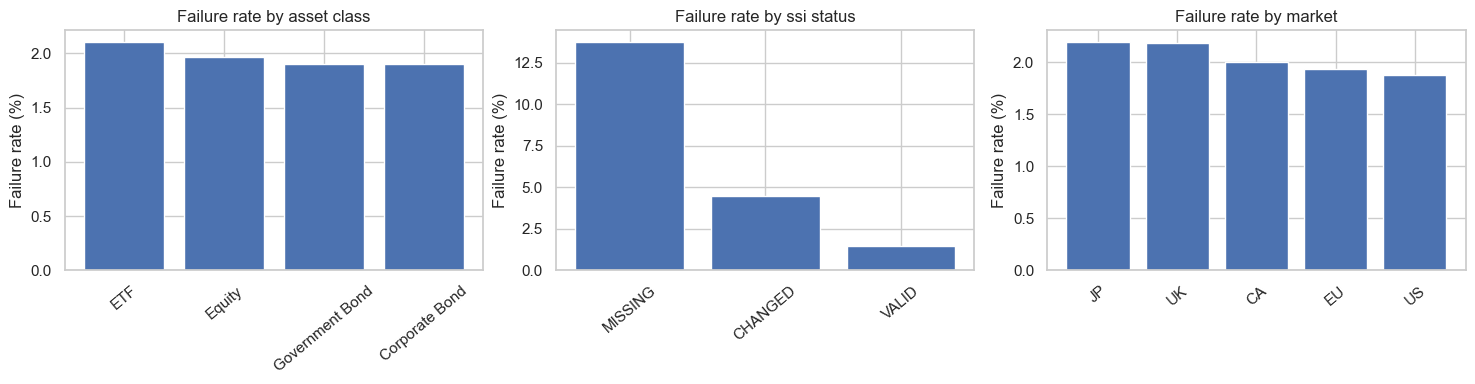

In [6]:
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['asset_class','ssi_status','market']):
    rates=clean.groupby(col).settlement_failed.agg(['mean','size']).sort_values('mean',ascending=False)
    ax.bar(rates.index.astype(str),rates['mean']*100)
    ax.set_title(f'Failure rate by {col.replace("_"," ")}')
    ax.set_ylabel('Failure rate (%)');ax.tick_params(axis='x',rotation=40)
plt.tight_layout();plt.show()

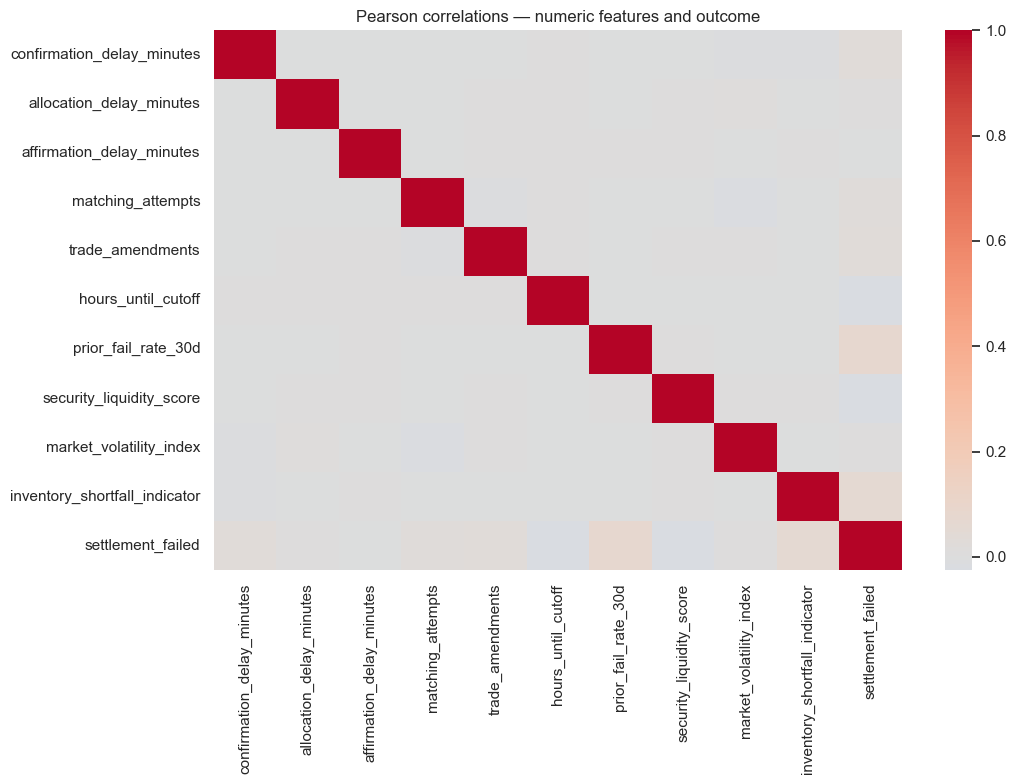

,Settled median,Failed median
confirmation_delay_minutes,26.7300,29.5700
matching_attempts,1.0000,1.0000
hours_until_cutoff,16.9700,15.8200
prior_fail_rate_30d,0.0785,0.1187
security_liquidity_score,0.6758,0.6454


In [7]:
cols=['confirmation_delay_minutes','allocation_delay_minutes','affirmation_delay_minutes','matching_attempts','trade_amendments','hours_until_cutoff','prior_fail_rate_30d','security_liquidity_score','market_volatility_index','inventory_shortfall_indicator','settlement_failed']
fig,ax=plt.subplots(figsize=(11,8));sns.heatmap(clean[cols].corr(),cmap='coolwarm',center=0,ax=ax);ax.set_title('Pearson correlations — numeric features and outcome');plt.tight_layout();plt.show()
summary=clean.groupby('settlement_failed')[['confirmation_delay_minutes','matching_attempts','hours_until_cutoff','prior_fail_rate_30d','security_liquidity_score']].median().T
summary.columns=['Settled median','Failed median'];display(summary)

## 5. Outlier assessment
IQR flags unusual observations, **not necessarily errors**. Rare large trades and operational delays may carry risk signal. Therefore, the baseline retains outliers and uses a robust interpretation of their effects; no blanket trimming is applied.

,variable,IQR_outliers,percent,min,max
0,trade_amount,2233,8.93,10000.00,1.200000e+08
1,quantity,2602,10.41,68.00,2.156350e+06
2,confirmation_delay_minutes,753,3.01,0.12,2.124600e+02
3,allocation_delay_minutes,848,3.39,0.03,1.367500e+02
4,affirmation_delay_minutes,816,3.26,0.04,1.955500e+02
5,hours_until_cutoff,87,0.35,0.50,4.439000e+01
6,trade_size_ratio,2550,10.20,0.02,4.000000e+01


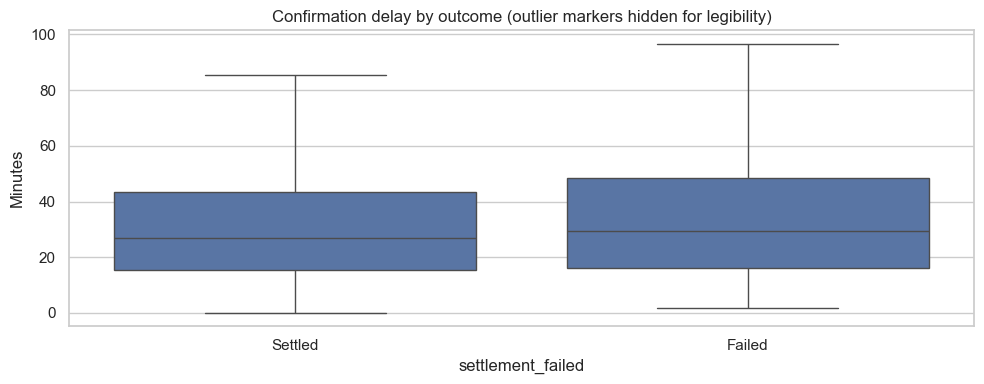

In [8]:
num_cols=['trade_amount','quantity','confirmation_delay_minutes','allocation_delay_minutes','affirmation_delay_minutes','hours_until_cutoff','trade_size_ratio']
rows=[]
for col in num_cols:
    q1,q3=clean[col].quantile([.25,.75]);iqr=q3-q1
    flagged=((clean[col]<q1-1.5*iqr)|(clean[col]>q3+1.5*iqr)).sum()
    rows.append({'variable':col,'IQR_outliers':int(flagged),'percent':round(100*flagged/len(clean),2),'min':clean[col].min(),'max':clean[col].max()})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(10,4));sns.boxplot(data=clean,x='settlement_failed',y='confirmation_delay_minutes',showfliers=False,ax=ax)
ax.set_xticks([0,1],['Settled','Failed']);ax.set_title('Confirmation delay by outcome (outlier markers hidden for legibility)');ax.set_ylabel('Minutes');plt.tight_layout();plt.show()

## 6. Feature engineering and leakage prevention
Create calendar features from **trade date** and transform trade size logarithmically. No feature may be derived from the settlement outcome, final failure reason, or realized delay. Temporal ordering is enforced before splitting. For realistic deployment, historical failure rates must be computed only from prior-known outcomes; here they are provided as synthetic pre-trade features.

In [9]:
work=clean.copy()
work['trade_weekday']=work.trade_date.dt.dayofweek.astype(str)
work['trade_month']=work.trade_date.dt.month.astype(str)
work['log_trade_amount']=np.log1p(work.trade_amount.clip(lower=0))
work['log_quantity']=np.log1p(work.quantity.clip(lower=0))
work['log_trade_size_ratio']=np.log1p(work.trade_size_ratio.clip(lower=0))
exclude={'trade_id','trade_date','settlement_date','settlement_failed','settlement_delay_hours','failure_reason','failure_reason_description','pre_settlement_note','trade_amount','quantity','trade_size_ratio'}
features=[c for c in work.columns if c not in exclude]
assert not set(features)&exclude
print('Predictor count:',len(features));print('Excluded leakage/identifier fields:',sorted(exclude))

Predictor count: 31
Excluded leakage/identifier fields: ['failure_reason', 'failure_reason_description', 'pre_settlement_note', 'quantity', 'settlement_date', 'settlement_delay_hours', 'settlement_failed', 'trade_amount', 'trade_date', 'trade_id', 'trade_size_ratio']


## 7. Temporal split and baseline model
Split chronologically into **70% training / 15% validation / 15% held-out test**. Module 20.1 reports only validation results; the test period is reserved for final Module 24 comparison. Preprocessing (median/mode imputation, one-hot encoding, scaling) is fitted on training only. The baseline is **class-weighted logistic regression**. Class weights improve learning from rare failures but may distort probability calibration; treat outputs as risk scores pending calibration. Compare against a constant-prevalence dummy baseline.

In [10]:
work=work.sort_values(['trade_date','trade_id']).reset_index(drop=True)
a=int(len(work)*.70);b=int(len(work)*.85)
train,val,test=work.iloc[:a],work.iloc[a:b],work.iloc[b:]
Xtr,ytr=train[features],train.settlement_failed
Xval,yval=val[features],val.settlement_failed
num=Xtr.select_dtypes(include='number').columns.tolist();cat=[c for c in features if c not in num]
prep=ColumnTransformer([
 ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num),
 ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
model=Pipeline([('preprocess',prep),('classifier',LogisticRegression(max_iter=1500,class_weight='balanced',random_state=42))])
model.fit(Xtr,ytr)
score=model.predict_proba(Xval)[:,1]
dummy=DummyClassifier(strategy='prior').fit(Xtr,ytr)
dummy_score=dummy.predict_proba(Xval)[:,1]
print('Training:',len(train),'Validation:',len(val),'Held-out test:',len(test))
print('Date windows:',train.trade_date.min().date(),train.trade_date.max().date(),'|',val.trade_date.min().date(),val.trade_date.max().date(),'|',test.trade_date.min().date(),test.trade_date.max().date())
print('Validation prevalence:',round(yval.mean(),5))

Training: 17500 Validation: 3750 Held-out test: 3750
Date windows: 2023-01-02 2025-01-13 | 2025-01-13 2025-06-19 | 2025-06-19 2025-11-28
Validation prevalence: 0.02053


,model,PR_AUC,ROC_AUC,precision_at_0.5,recall_at_0.5,F1_at_0.5
0,Dummy prior,0.0205,0.5000,0.0000,0.0000,0.0000
1,Logistic Regression,0.1085,0.7492,0.0453,0.6104,0.0843


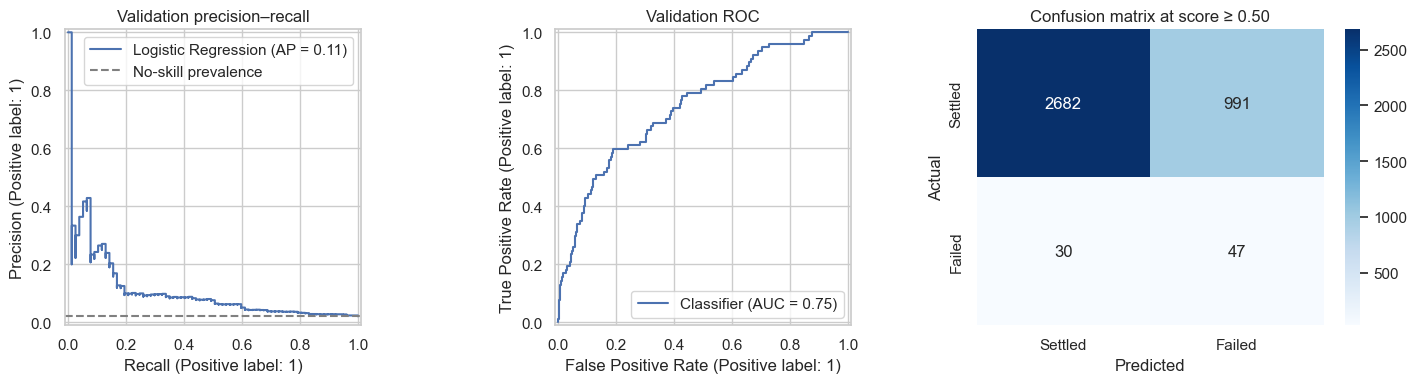

In [11]:
pred=(score>=.5).astype(int)
metrics=pd.DataFrame([
 {'model':'Dummy prior','PR_AUC':average_precision_score(yval,dummy_score),'ROC_AUC':roc_auc_score(yval,dummy_score),'precision_at_0.5':precision_score(yval,(dummy_score>=.5).astype(int),zero_division=0),'recall_at_0.5':recall_score(yval,(dummy_score>=.5).astype(int),zero_division=0),'F1_at_0.5':f1_score(yval,(dummy_score>=.5).astype(int),zero_division=0)},
 {'model':'Logistic Regression','PR_AUC':average_precision_score(yval,score),'ROC_AUC':roc_auc_score(yval,score),'precision_at_0.5':precision_score(yval,pred,zero_division=0),'recall_at_0.5':recall_score(yval,pred,zero_division=0),'F1_at_0.5':f1_score(yval,pred,zero_division=0)}])
display(metrics.round(4))
fig,axes=plt.subplots(1,3,figsize=(15,4))
PrecisionRecallDisplay.from_predictions(yval,score,ax=axes[0],name='Logistic Regression')
axes[0].axhline(yval.mean(),linestyle='--',color='gray',label='No-skill prevalence');axes[0].legend();axes[0].set_title('Validation precision–recall')
RocCurveDisplay.from_predictions(yval,score,ax=axes[1]);axes[1].set_title('Validation ROC')
sns.heatmap(confusion_matrix(yval,pred),annot=True,fmt='d',cmap='Blues',ax=axes[2],xticklabels=['Settled','Failed'],yticklabels=['Settled','Failed']);axes[2].set_title('Confusion matrix at score ≥ 0.50');axes[2].set_xlabel('Predicted');axes[2].set_ylabel('Actual')
plt.tight_layout();plt.show()

## 8. Interpretation, limitations, and Module 24 plan
**Interpretation:** PR-AUC evaluates ranking quality across precision/recall trade-offs and is more informative than accuracy for rare settlement failures. A dummy classifier's PR-AUC is approximately the validation failure prevalence. The 0.50 cutoff is illustrative; it is not an operationally optimized decision threshold. High recall with low precision may overwhelm an operations queue. **Do not use the test set for model or threshold selection.**

**Limitations:** All data and outcomes are synthetic; no SEC/FRED public records are represented as independently acquired in this module. Synthetic failure relationships may be easier to learn than real settlement behavior. Data quality audit on a clean source does not demonstrate real-world imputation effectiveness. Class-weighted probabilities are not necessarily calibrated. Trade date is a proxy for temporal availability; production would need event timestamps and data-latency checks.

**Module 24 next steps:** Compare additional models with temporal validation; tune hyperparameters and thresholds using training/validation only; consider calibration and operational review capacity; evaluate the chosen model once on untouched test; explain errors and business costs; document drift, fairness, governance, and deployment considerations.

In [12]:
from pathlib import Path
out=Path('outputs');out.mkdir(exist_ok=True)
metrics.to_csv(out/'module20_validation_baseline_metrics.csv',index=False)
pd.DataFrame([audit]).to_csv(out/'module20_data_quality_audit.csv',index=False)
print('Saved validation baseline metrics and quality audit to outputs/.')

Saved validation baseline metrics and quality audit to outputs/.
